# PYTORCH



In [34]:
import torch

## Tensor

- osnovna oblika torcha je tensor (neke vrste multi dimenziniran array)

Naredi se ga lahko:

- iz podatkov z `torch.tensor(podatki)`

- iz poljubne oblike `torch.ones/zeros/randn(oblika)`

- oponašanje že obstoječega tensorja `torch.rand_like(podatki, dtype=torch.float)`


Trije atributi tensorja so:

- oblika (vrstice in stolpci)
- podatkovni tip (najpogosteje float32, ker je se da minimalno spreminjati vrednosti, za razlike od int)
- device (cpu/gpu)


In [35]:
podatki =[[1,2,3],[4,5,6]]

moj_tensor=torch.tensor(podatki, dtype=torch.float32)

print(moj_tensor)

print()

oblika=(2,3)

random=torch.randn(oblika)

print(random)
print()

rand_kot_podatki= torch.rand_like(moj_tensor,dtype=torch.float) 

print(rand_kot_podatki) #oblika ista kot moj_tensor, vendar je vsebina drugačna


tensor([[1., 2., 3.],
        [4., 5., 6.]])

tensor([[ 1.6979,  2.1966, -0.3371],
        [-0.1034,  2.0700,  1.3219]])

tensor([[0.1044, 0.1629, 0.6020],
        [0.7300, 0.9217, 0.4125]])


In [36]:
print(f"Oblika: {moj_tensor.shape}")
print()
print(f"Podatkovni tip: {moj_tensor.dtype}")
print()
print(f"Device: {moj_tensor.device}")

Oblika: torch.Size([2, 3])

Podatkovni tip: torch.float32

Device: cpu


## AUTOGRAD

Autograd je PyTorchev sistem za samodejno odvajanje. Med računanjem si zapomni, katere operacije se izvede nad tenzorji, nato pa z verižnim pravilom izračuna gradiente (odvode) glede na vse parametre.

Vklopi se ga z `requires_grad=True`

Brez tega so tensorji zgolj podatki. Z tem pa postanejo učni parametri.

Z `.grad_fn` se gleda, kako je bil tensor narejen (v kateri operaciji).


In [37]:
a=torch.tensor(2.0, requires_grad=True)


## Operacije

### `*` vs `@`

`*` je množenje na podlagi elementov. Torej množi elemnt, ki je na isti poziciji v drugi matrici. Tu morata imeti obe matrici enako obliko. 

`@` je množenje matric. Ta je pomembnejša. 

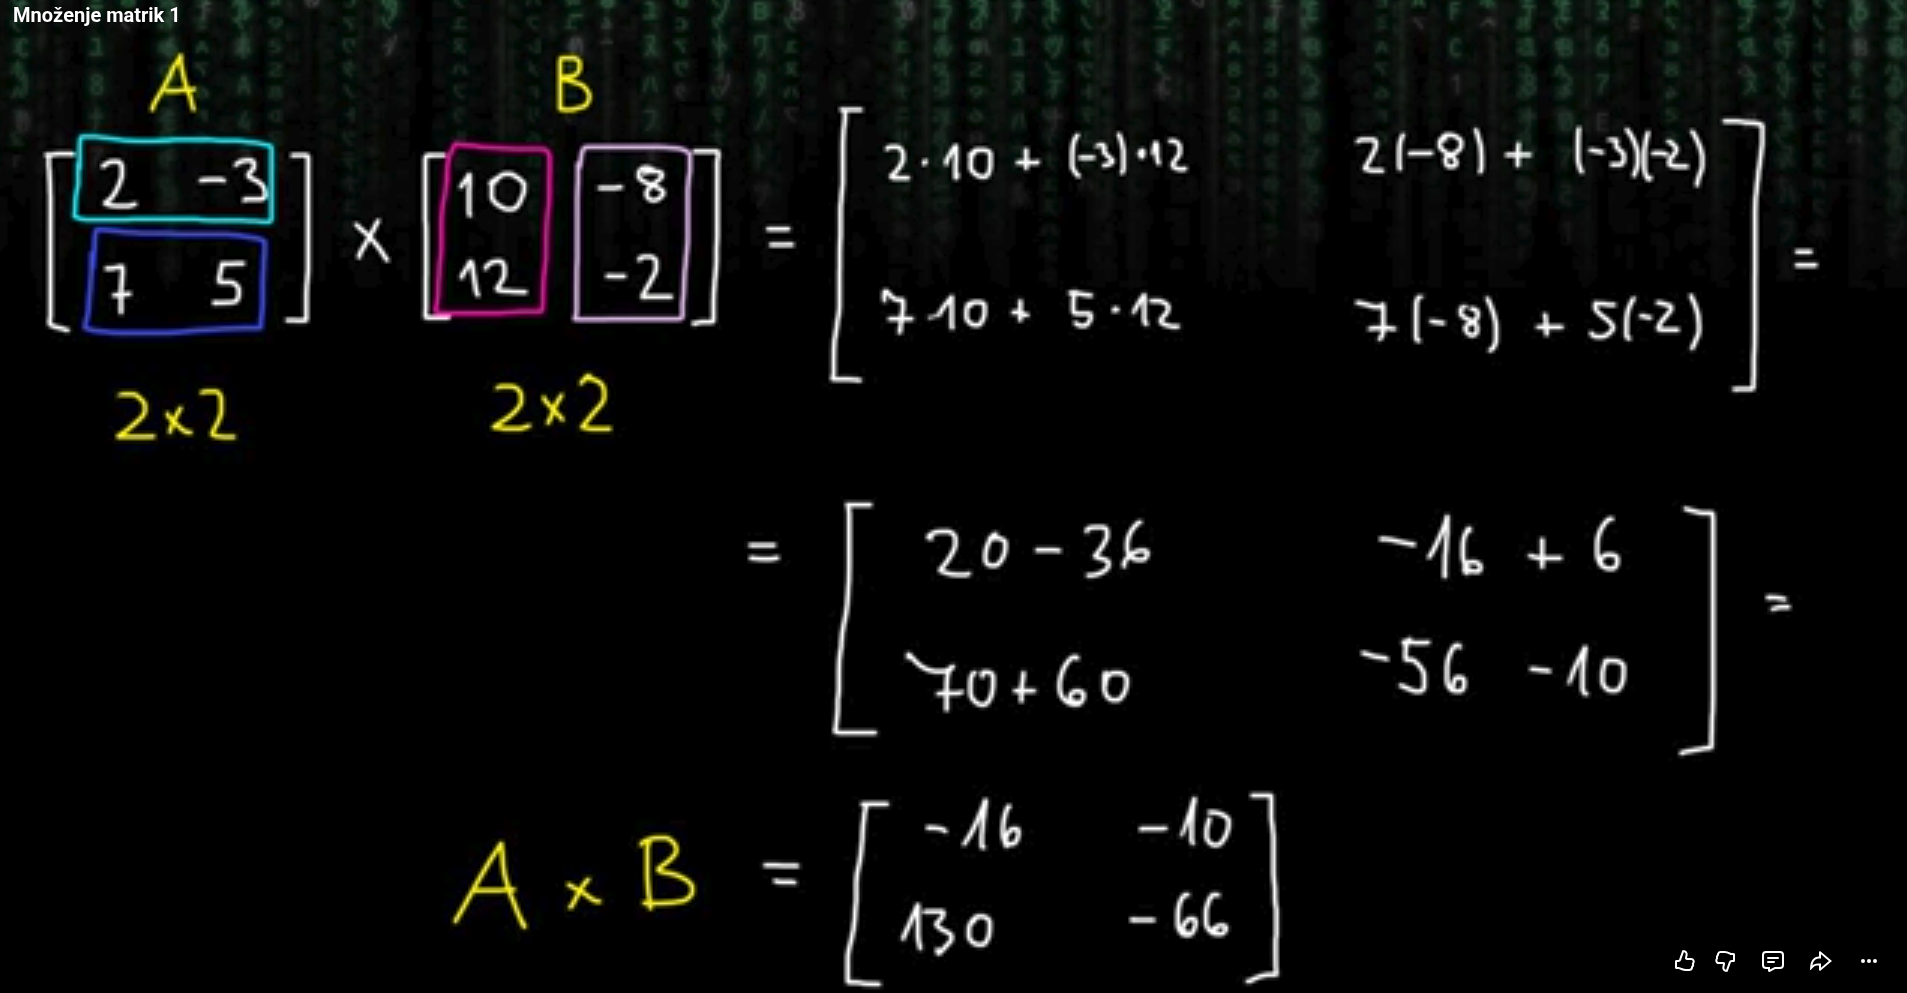 (vir 3)

Pri tem množenju se mora ujemati št. stolpcev prve matrice z številom vrdtic druge matrice. 






In [38]:
a=torch.tensor([[1,2],[3,4]])

b=torch.tensor([[10,20],[30,40]])

c= torch.tensor([[10,20,50],[30,40,60]])

print(f"Množenje z *: \n{(a*b)}")
print()
print(f"Monženje z @: \n{a@b}")
print()
print(f"Monženje z @: \n{a@c}")

Množenje z *: 
tensor([[ 10,  40],
        [ 90, 160]])

Monženje z @: 
tensor([[ 70, 100],
        [150, 220]])

Monženje z @: 
tensor([[ 70, 100, 170],
        [150, 220, 390]])


### Redukcija in `dim`

Redukcija se uporablja za zmanjševanje elemntov tensorja (mean, sum...).

Z `dim` se določi v katero smer se bo redukcija izvedla.

- `dim=0` : vertikalno

- `dim=1` : horizontalno

In [39]:
vrednosti=torch.tensor([[10,20,50],[30,40,60]], dtype=torch.float32)

print(f"Povprečje stolpcev: \n{vrednosti.mean(dim=0)}")
print()
print(f"Povprečje vrstic: \n{vrednosti.mean(dim=1)}")

Povprečje stolpcev: 
tensor([20., 30., 55.])

Povprečje vrstic: 
tensor([26.6667, 43.3333])


### Izbira podatkov

Deluje na podoben način kot pri numpy z indeksiranjem.

In [40]:
x=torch.arange(12).reshape(3,4)

print(x)
print()
print(f"Stolpec 3: \n{x[:,2]}") # v tem primeru : pomeni vse vrstice

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

Stolpec 3: 
tensor([ 2,  6, 10])


### Argmax

Uporablja se za iskanje največjih vresnosti. 

In [41]:
print(f"Indeks največje vrednosti v vrsticah: {torch.argmax(x,dim=1)}")

Indeks največje vrednosti v vrsticah: tensor([3, 3, 3])


### torch.gather()

Za iskanje določenih elementov.

In [42]:
podatki=torch.rand_like(x,dtype=torch.float32)
elementi_za_izbor=torch.tensor([[2],[0],[3]]) #indeksi željenih vrednosti

željene_vrednosti=torch.gather(podatki,dim=1, index=elementi_za_izbor) #dim=1 za horizontalen izbor (po vrsticah)

print(podatki)
print()
print(željene_vrednosti) #rezultat so izbrane vrednosti v vsaki vrstici



tensor([[0.6229, 0.3630, 0.2753, 0.2193],
        [0.6959, 0.5719, 0.5666, 0.0300],
        [0.8515, 0.7529, 0.7272, 0.6506]])

tensor([[0.2753],
        [0.6959],
        [0.6506]])


## Grajenje modela

### Forward pass
 
Forward pass je v bistvu modelov prvi ugib.

Model temelji na tej formuli: 

`ŷ=XW + b` kjer je X vnos, W utež, b pa bias. ŷ pa je modelova napoved oz. ugib.

Torej ko učimo model spreminjamo W in b.

In [43]:
#Podaki, ki sledijo liniji y=2x+1

N = 10 # naši podatki imajo 10 datapointov


# vsak data point ima en input feature in 1 output value

D_in=1 
D_out=1

#Input podatki

X=torch.randn(N, D_in)

print(X)
print()

# Naredimo pravilne target lable y z pravim W in pravim b
#Pravi W je 2.0 in pravi b je 1

praviln_W=torch.tensor([[2.0]])

praviln_b = torch.tensor(1.0)

# resnica
praviln_Y= X @ praviln_W +praviln_b +torch.randn(N, D_out) * 0.1  # 0.1 je za noise

print(praviln_Y)
print()

# Nraedimo začetne uteži in bias
W = torch.randn(D_in, D_out, requires_grad=True)
b = torch.randn(1, requires_grad=True)

print(f"Začetne uteži W: \n{W}\n")  # To je modelov prvotni ugib, ki je popolnoma napačen
print(f"Začetni bias b: \n{b}")

tensor([[ 0.6549],
        [ 0.6463],
        [ 0.7802],
        [ 0.7113],
        [-0.8790],
        [ 1.2434],
        [-0.8993],
        [ 0.5285],
        [-1.1005],
        [-0.0937]])

tensor([[ 2.3623],
        [ 2.3670],
        [ 2.5736],
        [ 2.5097],
        [-0.8756],
        [ 3.4940],
        [-0.9000],
        [ 1.9750],
        [-1.1906],
        [ 0.7626]])

Začetne uteži W: 
tensor([[-0.3107]], requires_grad=True)

Začetni bias b: 
tensor([-2.9576], requires_grad=True)


Formulo y=XW+b uporabimo v kodi:

`y_hat= X @ W +b`

In [44]:

y_hat= X @ W +b

print(f"Predikcija y_hat (prve tri vrstice): \n{y_hat[:3]}\n")
print(f"Pravilni label praviln_y (prve tri vrstice): \n{praviln_Y[:3]}")


Predikcija y_hat (prve tri vrstice): 
tensor([[-3.1611],
        [-3.1584],
        [-3.2000]], grad_fn=<SliceBackward0>)

Pravilni label praviln_y (prve tri vrstice): 
tensor([[2.3623],
        [2.3670],
        [2.5736]])


Rezultati y_hat se niti malo ne ujemajo z resnico (pravilni_Y).

### Backward pass

Ugotoviti kako napačen je bil forward pass ugib. To bomo ugotovili z loss.
Loss bomo ugotovili z mean squared error (MSE).

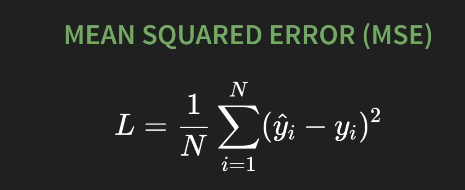

To pomeni, da bomo za vsako napoved:

1. `(y_hat - praviln_Y)`
2. nato bomo dobljeno dali na kvadrat, da dobimo pozitivno številko
3. Na koncu pa bomo izračunali povprečje teh vrednosti

V kodi to pomeni:

In [45]:
napaka=y_hat - praviln_Y
napaka_na_kvadrat= napaka ** 2

loss=napaka_na_kvadrat.mean()

print(f"Loss: {loss}")

Loss: 22.155330657958984


Zdaja rabimo ugotoviti za koliko spremeniti W in b da zmanjšamo loss. To bomo naredili z autogradom in sicer gradient lossa v odnosu do W (uteži) in gradient lossa v odnosu do b (biasa).

To bomo naredili z `loss.backward()` (tu pridejo v poštev vse vrednosti, ki imajo`requires_grad=True`)

In [46]:
loss.backward()

print(f"Gradient za W: \n{W.grad}\n")
print(f"Gradient za b: \n{b.grad}\n")

Gradient za W: 
tensor([[-4.3663]])

Gradient za b: 
tensor([-8.6297])



Negativen `.W.grad` pomeni pomeni, da če bomo povečali W, se bo loss zmanjšal

`.grad()` nam pove za koliko rabimo spremeniti W in b.

To ponovimo, dokler nismo zadovoljni z rezultatom. Temu se reče  **training loop** pri katerem se upošteva **gradient descent** .

### Algoritem gradient descent

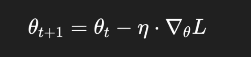

- Θ predstavlja vse parametre. V našem primeru W in b.

- η stopnja učenja. Ponavadi majhna številja (0.01), kki določa, kako velik korak naredimo pri vsaki posodobitvi parametrov.

- {\displaystyle \nabla } *L* predstavlja gradient lossa. Kar smo izračunali v prejšnem koraku (W.grad in b.grad)

v kodi to pomeni:

`nov_W = star_W - learning_rate * W.grad`

`nov_b = star_b - learning_rate * b.grad`

To ponavljamo čez več epoh. Ena epoha je en training loop.

### Training loop

Pomembni sta dve funkciji:

- `torch.no_grad()` ki sporoča torchu, da naj ne spremlja sprememb parametrov, saj jih bomo spreminjali ročno

- `.grad.zero_()` ki sporoča, da je potrebno resetirat gradiente po vsaki epohi. 

In [47]:
#hiperparametri

learning_rate, epohe= 0.01, 1000

#ponovno definiramo parametre (začeten ugib)
W, b =torch.randn(1,1, requires_grad=True), torch.randn(1, requires_grad=True)

#Training loop

for epoha in range(epohe):

    #forwardpass in loss
    y_hat = X @ W + b
    loss = torch.mean((y_hat-praviln_Y)**2)

    # backward pass
    loss.backward()

    #Update parametrov
    with torch.no_grad():
        W-=learning_rate * W.grad; b -= learning_rate * b.grad

    #resetiramo gradiente
    W.grad.zero_(); b.grad.zero_()


    # prikaz učenja modela
    if epoha % 10 == 0:
        print(f"Epoha {epoha:02d}: Loss={loss.item():.4f}, W={W.item():.3f}, b={b.item():.3f}")


print(f"\nFinalni paramteri: W={W.item():.3f}, b={b.item():.3f}") 

print("Pravi parametri W=2.000, b=1.000")

Epoha 00: Loss=6.4966, W=0.958, b=3.502
Epoha 10: Loss=4.5416, W=1.024, b=3.072
Epoha 20: Loss=3.2028, W=1.094, b=2.718
Epoha 30: Loss=2.2790, W=1.165, b=2.427
Epoha 40: Loss=1.6366, W=1.235, b=2.188
Epoha 50: Loss=1.1860, W=1.303, b=1.990
Epoha 60: Loss=0.8672, W=1.368, b=1.826
Epoha 70: Loss=0.6397, W=1.429, b=1.691
Epoha 80: Loss=0.4758, W=1.487, b=1.578


Epoha 90: Loss=0.3567, W=1.541, b=1.485
Epoha 100: Loss=0.2693, W=1.590, b=1.407
Epoha 110: Loss=0.2048, W=1.635, b=1.342
Epoha 120: Loss=0.1568, W=1.677, b=1.287
Epoha 130: Loss=0.1207, W=1.715, b=1.242
Epoha 140: Loss=0.0935, W=1.750, b=1.203
Epoha 150: Loss=0.0729, W=1.781, b=1.171
Epoha 160: Loss=0.0571, W=1.809, b=1.144
Epoha 170: Loss=0.0450, W=1.835, b=1.121
Epoha 180: Loss=0.0357, W=1.858, b=1.101
Epoha 190: Loss=0.0285, W=1.878, b=1.085
Epoha 200: Loss=0.0229, W=1.897, b=1.071
Epoha 210: Loss=0.0186, W=1.914, b=1.058
Epoha 220: Loss=0.0153, W=1.929, b=1.048
Epoha 230: Loss=0.0126, W=1.942, b=1.039
Epoha 240: Loss=0.0106, W=1.954, b=1.032
Epoha 250: Loss=0.0090, W=1.965, b=1.025
Epoha 260: Loss=0.0077, W=1.974, b=1.020
Epoha 270: Loss=0.0068, W=1.983, b=1.015
Epoha 280: Loss=0.0060, W=1.990, b=1.010
Epoha 290: Loss=0.0054, W=1.997, b=1.007
Epoha 300: Loss=0.0049, W=2.003, b=1.004
Epoha 310: Loss=0.0045, W=2.008, b=1.001
Epoha 320: Loss=0.0042, W=2.013, b=0.998
Epoha 330: Loss=0

Loss se je zmanjševal W in b pa sta postajala čedalje bližje pravima W in b.

## Modul torch.nn

Modul za gradnjo nevronskih mrež. Vsebuje vse gradnike, ki so potrebovane: plasti, aktivacijske funkcije, funkcije izgube in osnovni razred za svoje modele.

Najpomembnejša funkcija je:

- `torch.nn.Linear`: je zakar smo v prešnjem modelu uporabljali `X @ W + b`. Zapakira W in b v objekt.


In [48]:
# Input ima en feature, output pa eno vrednost

D_in=1
D_out=1

# Naredimo linarni sloj

linear_layer = torch.nn.Linear(in_features=D_in, out_features=D_out)

print(f"Linerne uteži (W): {linear_layer.weight}\n")

print(f"Linerne bias (b): {linear_layer.bias}\n")

# Uporablja se kot funkcijo. To je forward pass (prvi ugib)
# X je tensor [10, 1] iz prejšnjega poglavja

y_hat_nn = linear_layer(X)

print(f"Output nn.Liner (prve tri vrstice); \n{y_hat_nn[:3]}")

Linerne uteži (W): Parameter containing:
tensor([[0.4259]], requires_grad=True)

Linerne bias (b): Parameter containing:
tensor([0.3291], requires_grad=True)

Output nn.Liner (prve tri vrstice); 
tensor([[0.6080],
        [0.6044],
        [0.6614]], grad_fn=<SliceBackward0>)


Lahko vidimo da funkcija sama naredi uteži in bias ter da `requires_grad=True`

Torej **Parameter** je tensor, ki ima:
- `requires_grad=True`
- se sam naredi ob stavritvi modela
- sledi spremembam

Imajo pa slabost, da lahko prepoznajo samo premico. Torej ne delujejo z zahtevnimi inputi. 

Zato potrebujemo **aktivacijsko funkcijo**, ki vnese v mrežo nelinaernost.

### `nn.ReLu`

Rectefied linear unit. Deluje po principu, če je input negativen, ga naredi 0. 

In [49]:
relu = torch.nn.ReLU()
testni_podatki = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])

aktivirani_podatki = relu(testni_podatki)

print(f"Originalni podatki: {testni_podatki}")
print(f"Aktivirani podatki: {aktivirani_podatki}")

Originalni podatki: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
Aktivirani podatki: tensor([0.0000, 0.0000, 0.0000, 0.5000, 2.0000])


### `nn.GELU`

Gaussian error linear unit. Gladkejša verzija ReLu. Se uporablja v modernih transformerjih.

In [50]:
gelu = torch.nn.GELU()

testni_podatki = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])

aktivirani_podatki = gelu(testni_podatki)

print(f"Originalni podatki: {testni_podatki}")
print(f"Aktivirani podatki: {aktivirani_podatki}")


Originalni podatki: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
Aktivirani podatki: tensor([-0.0455, -0.1543,  0.0000,  0.3457,  1.9545])


### `nn.Softmax`

Uporablja se za zadnjo plast pri klasifikaciji. Konverta surove napovedi modela (logits) v distribucijo verjetnosti. Vrednosti bodo med 0 in 1, ter njihova vsota bo 1.

In [51]:
softmax= torch.nn.Softmax(dim=1)

# surove napovedi modelov za dva predmeta, čez 4 možne razrede

logits= torch.tensor([[1.0, 3.0, 0.5, 1.5], [-1.0, 2.0, 1.0, 0.0]])

verjetnosti=softmax(logits)

print(f"Verjetnosti outputa: \n{verjetnosti}\n")
print(f"Vsota verjetnosti za prvi predmet: {verjetnosti[0].sum()}")

Verjetnosti outputa: 
tensor([[0.0939, 0.6942, 0.0570, 0.1549],
        [0.0321, 0.6439, 0.2369, 0.0871]])

Vsota verjetnosti za prvi predmet: 1.0


# Končal na 46 min 

viri:
1. https://www.youtube.com/watch?v=r1bquDz5GGA&t=329s
2. https://www.youtube.com/watch?v=V_xro1bcAuA&t=2640s
3. https://www.youtube.com/watch?v=woSNI-aejnU